# Gradient Boosting from Scratch

## Objectives
- Understand boosting and sequential error correction.
- Implement Gradient Boosting for binary classification.
- Evaluate the model using classification metrics.
- Compare the implementation with Scikit-Learn.

**Dataset:** Synthetic binary classification dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

In [2]:
X, y = make_classification(
    n_samples=1000,
    n_features=5,
    n_informative=4,
    n_redundant=0,
    n_classes=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (800, 5)
Testing shape: (200, 5)


In [3]:
class GradientBoostingScratch:
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=2):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.trees = []

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)

        if not np.all(np.isin(y, [0, 1])):
            raise ValueError("Labels must be encoded as 0 and 1.")

        if len(np.unique(y)) != 2:
            raise ValueError("Training data must contain both classes.")

        self.initial_log_odds_ = np.log(
            np.mean(y) / (1 - np.mean(y))
        )

        raw_predictions = np.full(
            len(y), self.initial_log_odds_, dtype=float
        )
        self.trees = []
        self.train_log_loss_ = []

        for _ in range(self.n_estimators):
            probabilities = self.sigmoid(raw_predictions)

            # Negative gradient of binary log loss
            residuals = y - probabilities

            tree = DecisionTreeRegressor(
                max_depth=self.max_depth,
                random_state=42
            )
            tree.fit(X, residuals)

            # Fit leaf values to the logistic loss
            leaf_ids = tree.apply(X)

            for leaf_id in np.unique(leaf_ids):
                mask = leaf_ids == leaf_id
                p = probabilities[mask]
                residual = residuals[mask]

                numerator = np.sum(residual)
                denominator = np.sum(p * (1 - p))

                # Newton-style leaf-value update
                leaf_value = numerator / (denominator + 1e-12)
                tree.tree_.value[leaf_id, 0, 0] = leaf_value

            update = tree.predict(X)
            raw_predictions += self.learning_rate * update
            self.trees.append(tree)

            self.train_log_loss_.append(
                log_loss(y, self.sigmoid(raw_predictions), labels=[0, 1])
            )

        return self

    def decision_function(self, X):
        raw_predictions = np.full(
            X.shape[0], self.initial_log_odds_, dtype=float
        )

        for tree in self.trees:
            raw_predictions += self.learning_rate * tree.predict(X)

        return raw_predictions

    def predict_proba(self, X):
        probabilities = self.sigmoid(self.decision_function(X))
        return np.column_stack([1 - probabilities, probabilities])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [4]:
gb_scratch = GradientBoostingScratch(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2
)

gb_scratch.fit(X_train, y_train)

print("Training completed.")
print("Number of trees:", len(gb_scratch.trees))

Training completed.
Number of trees: 100


In [5]:
y_pred = gb_scratch.predict(X_test)

print("Gradient Boosting from Scratch")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Log Loss:  {log_loss(y_test, gb_scratch.predict_proba(X_test), labels=[0, 1]):.4f}")

Gradient Boosting from Scratch
-----------------------------------
Accuracy:  0.9000
Precision: 0.9072
Recall:    0.8889
F1-score:  0.8980
Log Loss:  0.2630


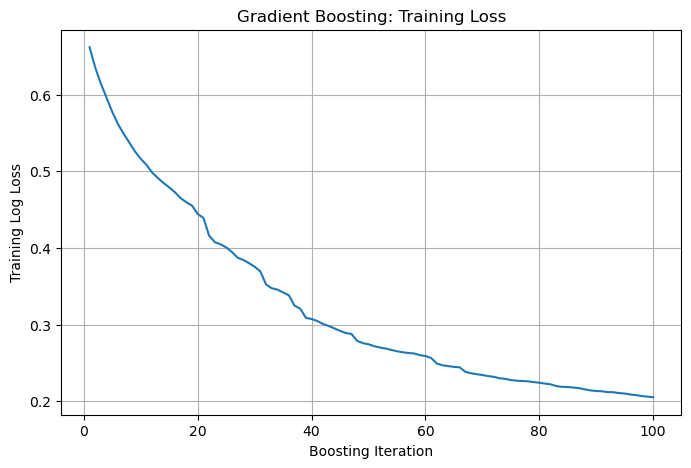

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(gb_scratch.train_log_loss_) + 1),
    gb_scratch.train_log_loss_
)
plt.xlabel("Boosting Iteration")
plt.ylabel("Training Log Loss")
plt.title("Gradient Boosting: Training Loss")
plt.grid(True)
plt.show()

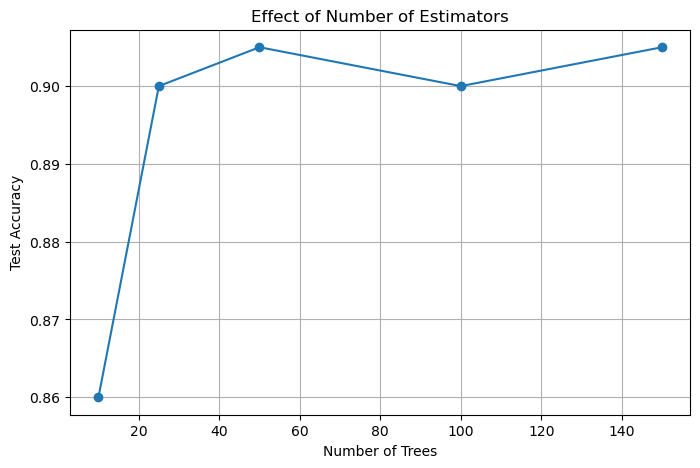

In [7]:
estimators = [10, 25, 50, 100, 150]
scores = []

for n in estimators:
    model = GradientBoostingScratch(
        n_estimators=n,
        learning_rate=0.1,
        max_depth=2
    )
    model.fit(X_train, y_train)
    scores.append(accuracy_score(y_test, model.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(estimators, scores, marker="o")
plt.xlabel("Number of Trees")
plt.ylabel("Test Accuracy")
plt.title("Effect of Number of Estimators")
plt.grid(True)
plt.show()

In [8]:
sklearn_gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    random_state=42
)

sklearn_gb.fit(X_train, y_train)

scratch_pred = gb_scratch.predict(X_test)
sklearn_pred = sklearn_gb.predict(X_test)

results = {
    "Model": ["Gradient Boosting (Scratch)", "Gradient Boosting (Sklearn)"],
    "Accuracy": [
        accuracy_score(y_test, scratch_pred),
        accuracy_score(y_test, sklearn_pred)
    ],
    "Precision": [
        precision_score(y_test, scratch_pred, zero_division=0),
        precision_score(y_test, sklearn_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, scratch_pred, zero_division=0),
        recall_score(y_test, sklearn_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, scratch_pred, zero_division=0),
        f1_score(y_test, sklearn_pred, zero_division=0)
    ]
}

import pandas as pd
pd.DataFrame(results).set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Gradient Boosting (Scratch),0.9,0.9072,0.8889,0.898
Gradient Boosting (Sklearn),0.9,0.9072,0.8889,0.898


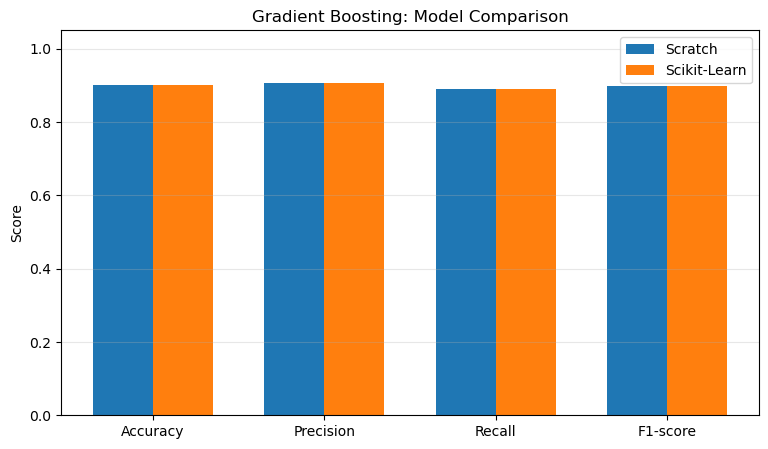

In [9]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
scratch_values = [
    accuracy_score(y_test, scratch_pred),
    precision_score(y_test, scratch_pred, zero_division=0),
    recall_score(y_test, scratch_pred, zero_division=0),
    f1_score(y_test, scratch_pred, zero_division=0)
]
sklearn_values = [
    accuracy_score(y_test, sklearn_pred),
    precision_score(y_test, sklearn_pred, zero_division=0),
    recall_score(y_test, sklearn_pred, zero_division=0),
    f1_score(y_test, sklearn_pred, zero_division=0)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width / 2, scratch_values, width, label="Scratch")
plt.bar(x + width / 2, sklearn_values, width, label="Scikit-Learn")
plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Gradient Boosting: Model Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()